# <center>**01 - Data Processing**<center>

Notebook đọc dữ liệu FER2013, chia tập theo cột `Usage`, kiểm tra phân bố nhãn và hiển thị dữ liệu mẫu. Sau đó, notebook tính thống kê chuẩn hóa từ tập Training và lưu các tập dữ liệu đã xử lý để tái sử dụng ở các bước tiếp theo.


In [1]:
import logging
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Tìm thư mục gốc dự án (nơi có requirements.txt) để notebook chạy được từ src/ hoặc notebooks/.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
            if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT / "src"))

from data_utils import (
    EMOTIONS,
    compute_mean_std,
    load_fer2013,
    load_kaggle_test,
    save_processed,
    split_arrays,
)

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(exist_ok=True)

log = logging.getLogger("data")
log.setLevel(logging.INFO)

if not log.handlers:  # Tránh thêm handler trùng khi chạy lại cell.
    fmt = logging.Formatter("%(asctime)s | %(name)s | %(levelname)s | %(message)s")
    fh = logging.FileHandler(LOG_DIR / f"data_{RUN_ID}.log", encoding="utf-8")
    sh = logging.StreamHandler()

    for handler in (fh, sh):
        handler.setFormatter(fmt)
        log.addHandler(handler)

log.info("Thư mục gốc: %s | Run ID: %s", ROOT, RUN_ID)

2026-11-23 15:11:12,844 | data | INFO | Thư mục gốc: d:\Programming\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 8 (Convolutional Neural Network)\Lab08b - Emotion Recognition | Run ID: 20261123_151112


## **1. Đọc và chia tập**

Đọc dữ liệu từ `icml_face_data.csv`, chuyển mỗi dòng pixel thành ảnh xám kích thước `48 × 48` và chia thành tập Training, Validation và Test dựa trên cột `Usage`.


In [2]:
CSV_PATH = ROOT / "data" / "icml_face_data.csv"
X, y, usage = load_fer2013(CSV_PATH)
splits = split_arrays(X, y, usage)

for name, (x_split, y_split) in splits.items():
    log.info(
        "%s: %d ảnh, shape mỗi ảnh %s",
        name,
        len(y_split),
        x_split.shape[1:],
    )

# Kiểm tra số lượng ảnh với số liệu của Kaggle và báo cáo của thầy.
expected = {"train": 28709, "valid": 3589, "test": 3589}

for name, count in expected.items():
    assert len(splits[name][1]) == count, f"{name}: {len(splits[name][1])} != {count}"

assert splits["train"][0].shape[1:] == (1, 48, 48)
log.info("Kiểm tra số lượng: OK")

2026-11-23 15:11:29,999 | data | INFO | train: 28709 ảnh, shape mỗi ảnh (1, 48, 48)
2026-11-23 15:11:30,000 | data | INFO | valid: 3589 ảnh, shape mỗi ảnh (1, 48, 48)
2026-11-23 15:11:30,001 | data | INFO | test: 3589 ảnh, shape mỗi ảnh (1, 48, 48)
2026-11-23 15:11:30,002 | data | INFO | Kiểm tra số lượng: OK


## **2. Phân bố nhãn**

Thống kê số lượng ảnh của từng cảm xúc trong ba tập. Biểu đồ histogram giúp kiểm tra mức độ cân bằng dữ liệu trước khi huấn luyện mô hình.


2026-11-23 15:11:30,015 | data | INFO | train: {'Angry': 3995, 'Disgust': 436, 'Fear': 4097, 'Happy': 7215, 'Sad': 4830, 'Surprise': 3171, 'Neutral': 4965}
2026-11-23 15:11:30,017 | data | INFO | valid: {'Angry': 467, 'Disgust': 56, 'Fear': 496, 'Happy': 895, 'Sad': 653, 'Surprise': 415, 'Neutral': 607}
2026-11-23 15:11:30,018 | data | INFO | test: {'Angry': 491, 'Disgust': 55, 'Fear': 528, 'Happy': 879, 'Sad': 594, 'Surprise': 416, 'Neutral': 626}


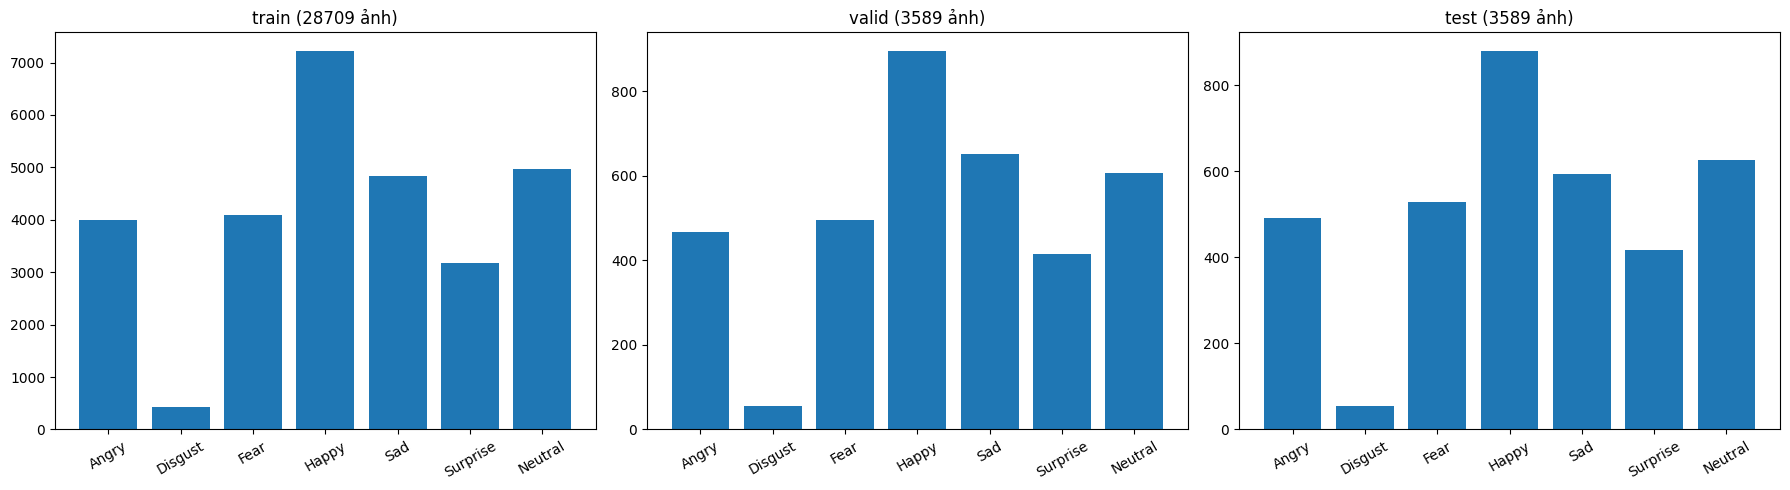

In [3]:
for name, (_, y_split) in splits.items():
    counts = np.bincount(y_split, minlength=len(EMOTIONS))
    log.info("%s: %s", name, dict(zip(EMOTIONS, counts.tolist())))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, (_, y_split)) in zip(axes, splits.items()):
    counts = np.bincount(y_split, minlength=len(EMOTIONS))
    ax.bar(EMOTIONS, counts)
    ax.set_title(f"{name} ({len(y_split)} ảnh)")
    ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(ROOT / "exps" / "eda_histogram.png", dpi=120)

plt.show()

## **3. Xem mẫu ảnh Training**

Chọn ngẫu nhiên 32 ảnh từ tập Training bằng seed cố định `42` để xem trực quan các nhãn cảm xúc và kiểm tra chất lượng dữ liệu.


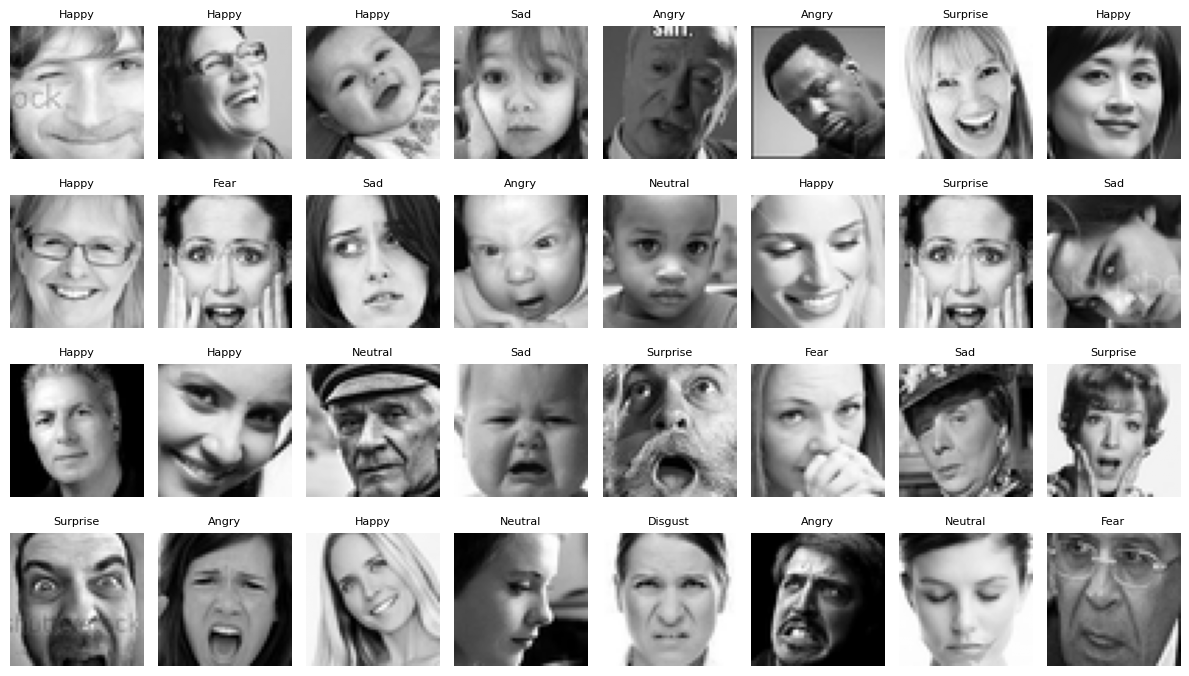

In [4]:
x_tr, y_tr = splits["train"]
rng = np.random.default_rng(42)
idx = rng.choice(len(x_tr), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(12, 7))

for ax, image_index in zip(axes.ravel(), idx):
    ax.imshow(x_tr[image_index, 0], cmap="gray")
    ax.set_title(EMOTIONS[y_tr[image_index]], fontsize=8)
    ax.axis("off")

fig.tight_layout()
fig.savefig(ROOT / "exps" / "train_samples.png", dpi=120)

plt.show()

## **4. Thống kê chuẩn hóa và lưu dữ liệu**

Tính `mean/std` chỉ trên tập Training để tránh rò rỉ dữ liệu. Hai giá trị này được lưu cùng các tập đã xử lý và dùng chung để chuẩn hóa tập Validation và Test.


In [5]:
mean, std = compute_mean_std(x_tr)
log.info("Mean=%.4f, Std=%.4f (chỉ tính trên Training)", mean, std)

PROCESSED = ROOT / "data" / "processed"
save_processed(splits, mean, std, PROCESSED)
log.info("Đã lưu splits và stats vào %s", PROCESSED)

2026-11-23 15:11:33,247 | data | INFO | Mean=0.5077, Std=0.2550 (chỉ tính trên Training)
2026-11-23 15:11:37,223 | data | INFO | Đã lưu splits và stats vào d:\Programming\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 8 (Convolutional Neural Network)\Lab08b - Emotion Recognition\data\processed


## **5. Đọc test.csv của Kaggle (không có nhãn)**

Đọc dữ liệu kiểm tra công khai của Kaggle, lưu dưới dạng NumPy array để phục vụ bước dự đoán sau này. Tập này không kèm nhãn cảm xúc.


In [6]:
X_kaggle = load_kaggle_test(ROOT / "data" / "test.csv")
np.save(PROCESSED / "kaggle_test_x.npy", X_kaggle)

log.info("test.csv: %d ảnh, shape %s", len(X_kaggle), X_kaggle.shape[1:])

2026-11-23 15:11:40,298 | data | INFO | test.csv: 7178 ảnh, shape (1, 48, 48)
